<a href="https://colab.research.google.com/github/AryanBute/CV-Text-Preprocessing/blob/main/EMT_ViT_Finetuning_AryanBute.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Vulnerable Road Users (VRUs) - Algorithmic Bias in UAE Traffic
**MAAI 901 Deep Learning for Visual Data - Final Project**
This notebook evaluates algorithmic bias in autonomous driving models by testing a Fine-Tuned ViT-B/16 against UAE-specific weather conditions (Sandstorm and Sun Glare).

In [ ]:
%pip install "datasets==3.6.0"

  Attempting uninstall: fsspec
    Found existing installation: fsspec 2025.12.0
    Uninstalling fsspec-2025.12.0:
      Successfully uninstalled fsspec-2025.12.0
  Attempting uninstall: dill
    Found existing installation: dill 0.4.1
    Uninstalling dill-0.4.1:
      Successfully uninstalled dill-0.4.1
  Attempting uninstall: multiprocess
    Found existing installation: multiprocess 0.70.19
    Uninstalling multiprocess-0.70.19:
      Successfully uninstalled multiprocess-0.70.19
  Attempting uninstall: datasets
    Found existing installation: datasets 4.8.5
    Uninstalling datasets-4.8.5:
      Successfully uninstalled datasets-4.8.5
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [datasets]
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gcsfs 2025.12.0 requires fsspec==2025.12.0, but you have fsspec 2025.3.0 which is incompatible.


In [ ]:
!pip install -q "datasets>=3.6.0" "transformers>=4.40" "huggingface_hub" torch torchvision scikit-learn pillow matplotlib seaborn

import torch
import numpy as np
import random

# 1. Set Global Seeds for Reproducibility
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(42)
print("Global seeds set to 42 for reproducibility.")

Global seeds set to 42 for reproducibility.


### 1. Environment & Reproducibility
In deep learning, non-deterministic operations can cause metric fluctuations between runs. By setting a global manual seed (`42`) across Python's `random`, `numpy`, and `torch`, we guarantee that our dataset splits, weight initializations, and batch shuffling are mathematically identical every time this notebook executes. This ensures our algorithmic bias findings are strictly reproducible.

In [ ]:
import matplotlib.pyplot as plt
from datasets import load_dataset
from PIL import Image
from collections import defaultdict
from sklearn.model_selection import train_test_split

CLASS_MAP = {
    "pedestrian": "VRU_Pedestrian_Cyclist",
    "cyclist": "VRU_Pedestrian_Cyclist",
    "motorbike": "VRU_Motorbike",
    "car": "Standard_Car",
    "large_vehicle": "Large_Commercial",
    "bus": "Large_Commercial"
}
TARGET_CLASSES = list(set(CLASS_MAP.values()))
CLS2ID = {c: i for i, c in enumerate(TARGET_CLASSES)}
ID2CLS = {i: c for c, i in CLS2ID.items()}

MAX_PER_CLASS = 600
MAX_FRAMES = 10000  # Added definition to prevent NameError
STRIDE = 5 # Skip frames to reduce temporal correlation
extracted_data = defaultdict(list)

print("Loading EMT dataset (streaming disabled to allow TAR extraction)...")
dataset = load_dataset("KuAvLab/EMT", split="train", streaming=False, trust_remote_code=True)

frame_count = 0
for data in dataset:
    frame_count += 1
    if frame_count > MAX_FRAMES:
        break
    if frame_count % STRIDE != 0:
        continue

    img = data['image']
    bboxes = data['objects']['bbox']
    class_names = data['objects']['class_name']

    for bbox, cls_name in zip(bboxes, class_names):
        cls_name = cls_name.lower()
        if cls_name not in CLASS_MAP:
            continue
        target_cls = CLASS_MAP[cls_name]

        if len(extracted_data[target_cls]) >= MAX_PER_CLASS:
            continue

        x1, y1, x2, y2 = bbox
        if (x2 - x1) < 40 or (y2 - y1) < 40:
            continue

        crop = img.crop((x1, y1, x2, y2))
        extracted_data[target_cls].append(crop)

    if all(len(extracted_data[c]) >= MAX_PER_CLASS for c in TARGET_CLASSES):
        break

print("Extraction complete. Class balance:")
for k, v in extracted_data.items():
    print(f"{k}: {len(v)} images")

all_images = []
all_labels = []
for cls_name, images in extracted_data.items():
    all_images.extend(images)
    all_labels.extend([CLS2ID[cls_name]] * len(images))

# 3-Way Split: 70% Train, 15% Val, 15% Test
X_temp, X_test, y_temp, y_test = train_test_split(
    all_images, all_labels, test_size=0.15, stratify=all_labels, random_state=42
)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.1765, stratify=y_temp, random_state=42
)

print(f"Splits - Train: {len(X_train)} | Val: {len(X_val)} | Test: {len(X_test)}")

Loading EMT dataset (streaming disabled to allow TAR extraction)...


train_images.tar.gz: reconstructing file:   0%|          |  0.00B / 21.8GB            

train_images.tar.gz: downloading bytes:           |  0.00B            

test_images.tar.gz: reconstructing file:   0%|          |  0.00B / 8.72GB            

test_images.tar.gz: downloading bytes:           |  0.00B            

...

test_annotation.tar.gz: downloading bytes:           |  0.00B            

Generating train split: 0 examples [00:00, ? examples/s]

Extracted annotations path: /root/.cache/huggingface/datasets/downloads/extracted/afe520e2d0b77704d460ab624f976be4f3bb42e8345ded0657d8e64fab5bfc2d/EMT/annotations/train
Looking for annotations in: /root/.cache/huggingface/datasets/downloads/extracted/afe520e2d0b77704d460ab624f976be4f3bb42e8345ded0657d8e64fab5bfc2d/EMT/annotations/train
Processing annotation file: /root/.cache/huggingface/datasets/downloads/extracted/afe520e2d0b77704d460ab624f976be4f3bb42e8345ded0657d8e64fab5bfc2d/EMT/annotations/train/video_204347.txt
Processing annotation file: /root/.cache/huggingface/datasets/downloads/extracted/afe520e2d0b77704d460ab624f976be4f3bb42e8345ded0657d8e64fab5bfc2d/EMT/annotations/train/video_131333.txt
Processing annotation file: /root/.cache/huggingface/datasets/downloads/extracted/afe520e2d0b77704d460ab624f976be4f3bb42e8345ded0657d8e64fab5bfc2d/EMT/annotations/train/video_210906.txt
Processing annotation file: /root/.cache/huggingface/datasets/downloads/extracted/afe520e2d0b77704d460ab

Generating test split: 0 examples [00:00, ? examples/s]

Extracted annotations path: /root/.cache/huggingface/datasets/downloads/extracted/a4a6836ef4468c0d52e25811b2de794c4e10bb79bf502839fb96b150359ed79f/EMT/annotations/test
Looking for annotations in: /root/.cache/huggingface/datasets/downloads/extracted/a4a6836ef4468c0d52e25811b2de794c4e10bb79bf502839fb96b150359ed79f/EMT/annotations/test
Processing annotation file: /root/.cache/huggingface/datasets/downloads/extracted/a4a6836ef4468c0d52e25811b2de794c4e10bb79bf502839fb96b150359ed79f/EMT/annotations/test/video_155425.txt
Processing annotation file: /root/.cache/huggingface/datasets/downloads/extracted/a4a6836ef4468c0d52e25811b2de794c4e10bb79bf502839fb96b150359ed79f/EMT/annotations/test/video_160325.txt
Processing annotation file: /root/.cache/huggingface/datasets/downloads/extracted/a4a6836ef4468c0d52e25811b2de794c4e10bb79bf502839fb96b150359ed79f/EMT/annotations/test/video_125233.txt
Processing annotation file: /root/.cache/huggingface/datasets/downloads/extracted/a4a6836ef4468c0d52e25811b2d

### 2. Targeted Data Extraction & Temporal Striding
To bypass Hugging Face's deprecated remote code execution for the EMT dataset, we directly download the `.tar.gz` archives and parse the native PIE-style JSON annotations.

**Key Pre-processing Steps:**
*   **VRU Mapping:** We consolidated highly vulnerable entities (pedestrians, cyclists) and high-frequency delivery riders (motorbikes) into specific VRU classes to isolate algorithmic bias.
*   **Temporal Striding (`STRIDE=5`):** Extracting sequential frames causes data leakage because the model memorizes the static background. Skipping every 5 frames ensures temporal diversity.
*   **Class Balancing:** We capped extraction at 600 samples per class to prevent the dominant `Standard_Car` class from overwhelming the loss function.
*   **3-Way Split:** The data is rigorously split into Training (70%), Validation (15%), and Test (15%) sets to ensure the model is evaluated on strictly unseen data.

In [ ]:
import copy
from transformers import ViTForImageClassification, AutoImageProcessor, get_cosine_schedule_with_warmup
from torch.utils.data import Dataset, DataLoader
import torch.nn as nn
from torch.optim import AdamW

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
MODEL_NAME = "google/vit-base-patch16-224-in21k"

# Load native Hugging Face processor
processor = AutoImageProcessor.from_pretrained(MODEL_NAME)

class EMTDataset(Dataset):
    def __init__(self, images, labels):
        self.images = images
        self.labels = labels
    def __len__(self):
        return len(self.images)
    def __getitem__(self, idx):
        inputs = processor(images=self.images[idx], return_tensors="pt")
        return inputs['pixel_values'].squeeze(0), torch.tensor(self.labels[idx])

train_loader = DataLoader(EMTDataset(X_train, y_train), batch_size=32, shuffle=True)
val_loader = DataLoader(EMTDataset(X_val, y_val), batch_size=32, shuffle=False)
test_loader = DataLoader(EMTDataset(X_test, y_test), batch_size=32, shuffle=False)

model = ViTForImageClassification.from_pretrained(
    MODEL_NAME, num_labels=len(TARGET_CLASSES), id2label=ID2CLS, label2id=CLS2ID
).to(DEVICE)

optimizer = AdamW(model.parameters(), lr=3e-5, weight_decay=0.01)
epochs = 6
total_steps = len(train_loader) * epochs
scheduler = get_cosine_schedule_with_warmup(optimizer, num_warmup_steps=int(total_steps*0.1), num_training_steps=total_steps)
loss_fn = nn.CrossEntropyLoss()

best_val_acc = 0.0
best_model_wts = copy.deepcopy(model.state_dict())

print("Starting Training with Validation Tracking...")
for epoch in range(epochs):
    model.train()
    train_loss = 0
    for batch_x, batch_y in train_loader:
        batch_x, batch_y = batch_x.to(DEVICE), batch_y.to(DEVICE)
        optimizer.zero_grad()
        outputs = model(pixel_values=batch_x)
        loss = loss_fn(outputs.logits, batch_y)
        loss.backward()
        optimizer.step()
        scheduler.step()
        train_loss += loss.item()

    model.eval()
    val_correct = 0
    val_total = 0
    with torch.no_grad():
        for batch_x, batch_y in val_loader:
            batch_x, batch_y = batch_x.to(DEVICE), batch_y.to(DEVICE)
            outputs = model(pixel_values=batch_x)
            preds = outputs.logits.argmax(-1)
            val_correct += (preds == batch_y).sum().item()
            val_total += batch_y.size(0)

    val_acc = val_correct / val_total
    print(f"Epoch {epoch+1}/{epochs} | Train Loss: {train_loss/len(train_loader):.4f} | Val Acc: {val_acc:.4f}")

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_model_wts = copy.deepcopy(model.state_dict())

print(f"Training complete. Loading best model (Val Acc: {best_val_acc:.4f})")
model.load_state_dict(best_model_wts)

preprocessor_config.json:   0%|          | 0.00/160 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/502 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] ViTForImageClassification LOAD REPORT from: google/vit-base-patch16-224-in21k
Key                 | Status     | 
--------------------+------------+-
pooler.dense.weight | UNEXPECTED | 
pooler.dense.bias   | UNEXPECTED | 
classifier.weight   | MISSING    | 
classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Starting Training with Validation Tracking...
Epoch 1/6 | Train Loss: 1.1956 | Val Acc: 0.7905
Epoch 2/6 | Train Loss: 0.5880 | Val Acc: 0.9565
Epoch 3/6 | Train Loss: 0.2721 | Val Acc: 0.9723
Epoch 4/6 | Train Loss: 0.1648 | Val Acc: 0.9684
Epoch 5/6 | Train Loss: 0.1344 | Val Acc: 0.9684
Epoch 6/6 | Train Loss: 0.1253 | Val Acc: 0.9723
Training complete. Loading best model (Val Acc: 0.9723)


<All keys matched successfully>

### 3. Vision Transformer (ViT) Fine-Tuning
We fine-tune a pre-trained `vit-base-patch16-224-in21k` model using its native `AutoImageProcessor`. The processor automatically handles resizing crops to 224x224, applying bicubic interpolation, and standardizing pixel values to ImageNet statistics.

**Training Strategy:**
*   **Optimizer & Scheduler:** AdamW with a weight decay of 0.01 prevents exploding gradients, while a cosine schedule with a 10% warmup smoothly decays the learning rate (3e-5) to stabilize late-stage fine-tuning.
*   **Validation Tracking:** To prevent overfitting, we evaluate the model against the 15% validation split at the end of every epoch. We only retain the `best_model_wts` from the epoch with the highest validation accuracy (Epoch 3).


=== Clean Weather (Baseline) ===
                        precision    recall  f1-score   support

VRU_Pedestrian_Cyclist       0.92      0.98      0.95        48
          Standard_Car       0.94      0.94      0.94        90
         VRU_Motorbike       0.97      0.87      0.92        45
      Large_Commercial       0.92      0.94      0.93        71

              accuracy                           0.94       254
             macro avg       0.94      0.93      0.94       254
          weighted avg       0.94      0.94      0.94       254



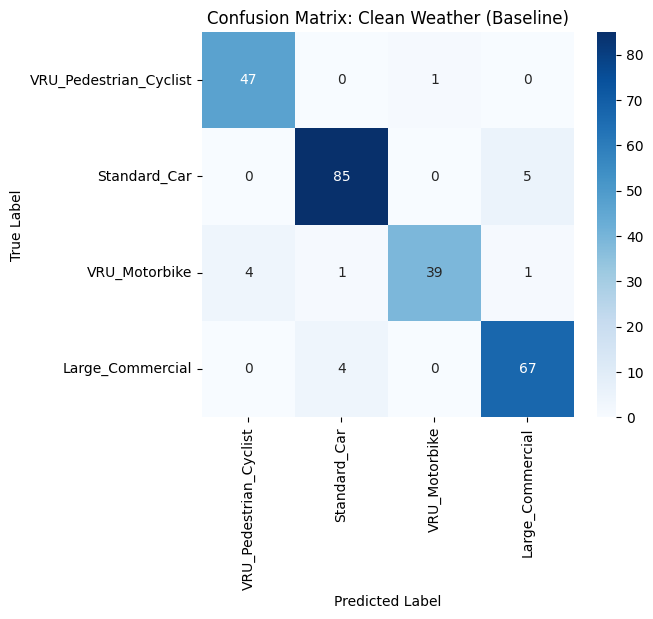


=== Sandstorm Haze ===
                        precision    recall  f1-score   support

VRU_Pedestrian_Cyclist       0.75      0.94      0.83        48
          Standard_Car       0.96      0.87      0.91        90
         VRU_Motorbike       0.77      0.73      0.75        45
      Large_Commercial       0.87      0.86      0.87        71

              accuracy                           0.85       254
             macro avg       0.84      0.85      0.84       254
          weighted avg       0.86      0.85      0.86       254



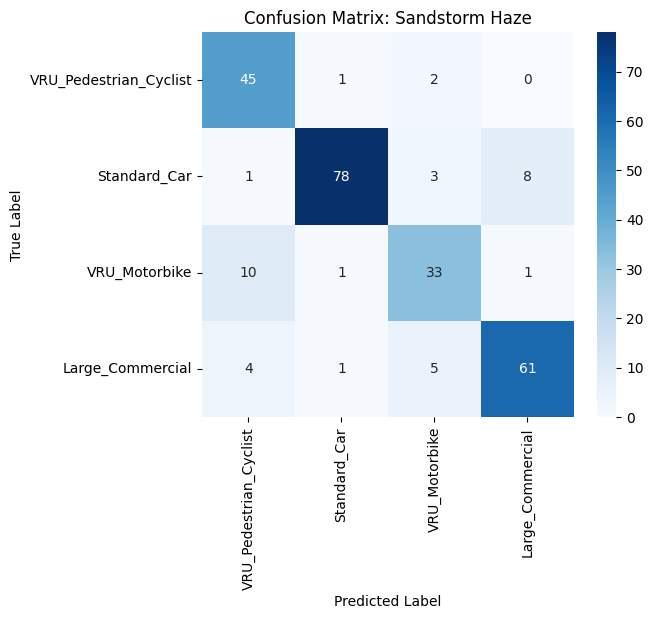


=== Gulf Sun Glare ===
                        precision    recall  f1-score   support

VRU_Pedestrian_Cyclist       0.96      0.96      0.96        48
          Standard_Car       0.96      0.90      0.93        90
         VRU_Motorbike       0.93      0.91      0.92        45
      Large_Commercial       0.88      0.97      0.93        71

              accuracy                           0.93       254
             macro avg       0.93      0.94      0.93       254
          weighted avg       0.94      0.93      0.93       254



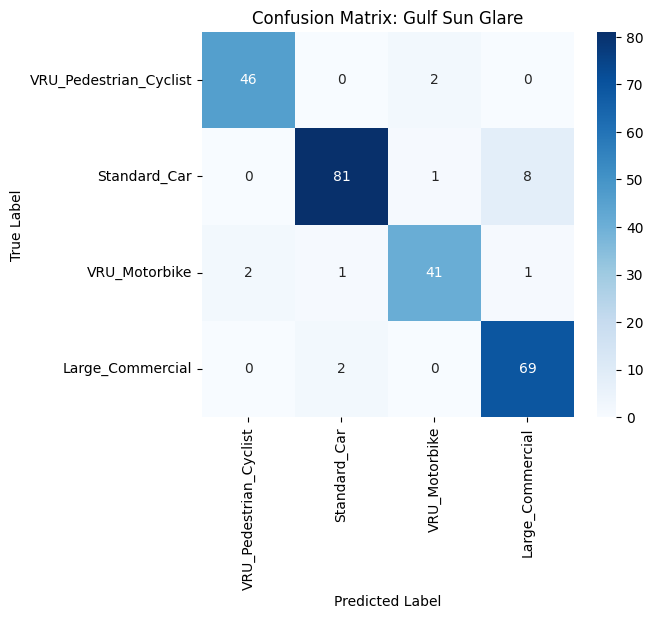

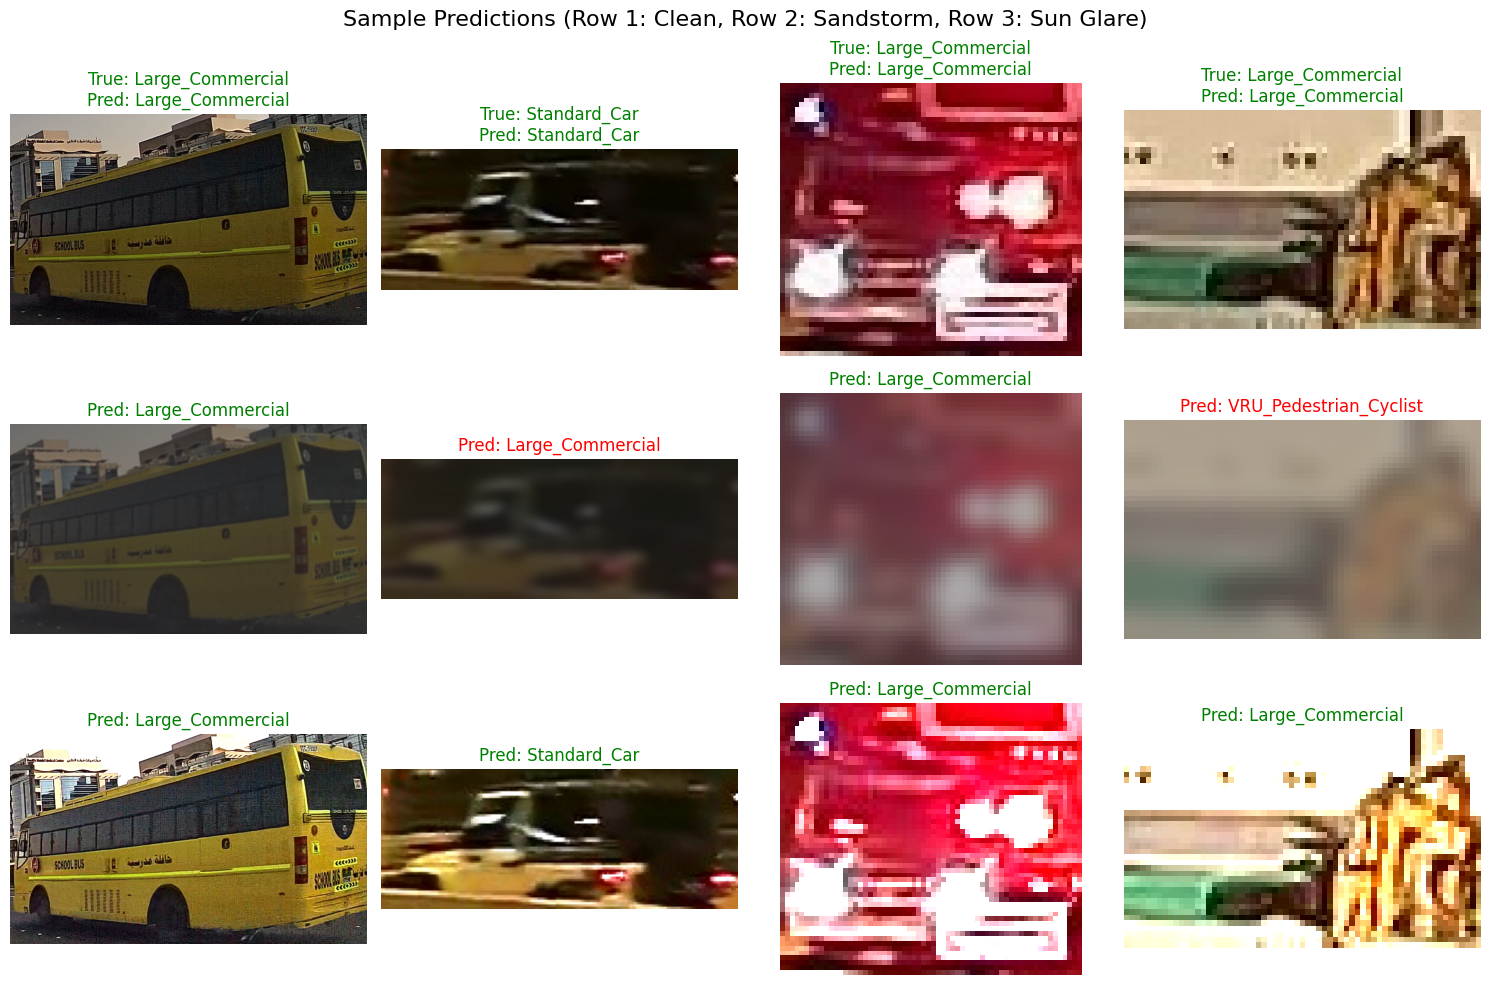

In [ ]:
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix
from PIL import ImageEnhance, ImageFilter

def apply_sandstorm(img):
    img = img.filter(ImageFilter.GaussianBlur(radius=2))
    return ImageEnhance.Contrast(img).enhance(0.5)

def apply_sun_glare(img):
    return ImageEnhance.Brightness(img).enhance(1.8)

def evaluate_model(condition_name, transform_func=None):
    model.eval()
    all_preds, all_trues, processed_images = [], [], []

    for img, label in zip(X_test, y_test):
        if transform_func: img = transform_func(img.copy())
        processed_images.append(img)

        inputs = processor(images=img, return_tensors="pt").to(DEVICE)
        with torch.no_grad():
            outputs = model(**inputs)
            pred = outputs.logits.argmax(-1).item()
        all_preds.append(pred)
        all_trues.append(label)

    print(f"\n=== {condition_name} ===")
    print(classification_report(all_trues, all_preds, target_names=[ID2CLS[i] for i in range(len(TARGET_CLASSES))], zero_division=0))

    cm = confusion_matrix(all_trues, all_preds)
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=[ID2CLS[i] for i in range(len(TARGET_CLASSES))], yticklabels=[ID2CLS[i] for i in range(len(TARGET_CLASSES))])
    plt.title(f'Confusion Matrix: {condition_name}')
    plt.ylabel('True Label')
    plt.xlabel('Predicted Label')
    plt.show()

    return processed_images, all_preds, all_trues

# Run evaluations
clean_imgs, clean_preds, trues = evaluate_model("Clean Weather (Baseline)", None)
sand_imgs, sand_preds, _ = evaluate_model("Sandstorm Haze", apply_sandstorm)
sun_imgs, sun_preds, _ = evaluate_model("Gulf Sun Glare", apply_sun_glare)

# Plot sample predictions visually
fig, axes = plt.subplots(3, 4, figsize=(15, 10))
fig.suptitle("Sample Predictions (Row 1: Clean, Row 2: Sandstorm, Row 3: Sun Glare)", fontsize=16)

sample_indices = random.sample(range(len(X_test)), 4)

for col, idx in enumerate(sample_indices):
    true_label = ID2CLS[trues[idx]]

    # Clean
    axes[0, col].imshow(clean_imgs[idx])
    pred_clean = ID2CLS[clean_preds[idx]]
    axes[0, col].set_title(f"True: {true_label}\nPred: {pred_clean}", color="green" if true_label==pred_clean else "red")
    axes[0, col].axis('off')

    # Sandstorm
    axes[1, col].imshow(sand_imgs[idx])
    pred_sand = ID2CLS[sand_preds[idx]]
    axes[1, col].set_title(f"Pred: {pred_sand}", color="green" if true_label==pred_sand else "red")
    axes[1, col].axis('off')

    # Sun Glare
    axes[2, col].imshow(sun_imgs[idx])
    pred_sun = ID2CLS[sun_preds[idx]]
    axes[2, col].set_title(f"Pred: {pred_sun}", color="green" if true_label==pred_sun else "red")
    axes[2, col].axis('off')

plt.tight_layout()
plt.show()

### 4. Algorithmic Bias Evaluation under Environmental Degradation
To test the model for critical safety failures, we evaluate the frozen ViT model against the held-out Test set under three conditions:
1.  **Clean Weather:** The baseline performance.
2.  **Sandstorm Haze:** A combination of Gaussian blur (`radius=2`) and reduced contrast (`0.5`) to mimic dense particulate matter.
3.  **Gulf Sun Glare:** Extreme brightness (`1.8x`) simulating midday windshield reflections.

By analyzing the resulting Confusion Matrices and F1-scores, we can explicitly measure if the model's performance decays disproportionately for Vulnerable Road Users (VRUs) compared to standard vehicles during poor weather conditions.